In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data_raw_Bird_2024 = pd.read_csv("Bird Torino - 2024 - Sheet1.csv", low_memory=False)

In [4]:
data_raw_Bird_2025 = pd.read_csv("Bird Torino - 2025 - Sheet1.csv", low_memory=False)

In [5]:
data_raw_Bird_2024.head()

,ID_VEICOLO,DATAORA_INIZIO,DATAORA_FINE,LATITUDINE_INIZIO_CORSA,LONGITUTIDE_INIZIO_CORSA,LATITUDINE_FINE_CORSA,LONGITUTIDE_FINE_CORSA,PERCORSO,DISTANZA_KM,DURATA_MIN,RISERVATO
0,8AD7P,"2024-1-1, 1:00","2024-1-1, 1:22",45.071664,7.695770,45.058830,7.678815,NaN,3.20,22.05,NaN
1,XN4B6,"2024-1-1, 1:00","2024-1-1, 1:03",45.052023,7.674939,45.052862,7.679611,NaN,0.50,3.08,NaN
2,JQ2JD,"2024-1-1, 1:02","2024-1-1, 1:29",45.066525,7.682050,45.055685,7.672043,NaN,1.80,27.20,NaN
3,BD8V5,"2024-1-1, 1:02","2024-1-1, 1:14",45.066468,7.681988,45.056301,7.673063,NaN,1.50,11.92,NaN
4,2YBLH,"2024-1-1, 1:03","2024-1-1, 1:22",45.061798,7.680334,45.064752,7.694430,NaN,2.71,18.35,NaN


In [6]:
data_raw_Bird_2025.head()

,ID_VEICOLO,DATAORA_INIZIO,DATAORA_FINE,LATITUDINE_INIZIO_CORSA,LONGITUTIDE_INIZIO_CORSA,LATITUDINE_FINE_CORSA,LONGITUTIDE_FINE_CORSA,PERCORSO,DISTANZA_KM,DURATA_MIN,RISERVATO
0,5KYFU,"2025-1-1, 0:04","2025-1-1, 0:08",45.069302,7.688246,45.065448,7.693584,NaN,0.9,4.15,NaN
1,FKNF6,"2025-1-1, 0:05","2025-1-1, 0:07",45.015912,7.662320,45.011909,7.665284,NaN,0.6,2.13,NaN
2,H8T49,"2025-1-1, 0:06","2025-1-1, 0:30",45.064871,7.694514,45.030423,7.655411,NaN,8.1,23.73,NaN
3,HLPII,"2025-1-1, 0:10","2025-1-1, 0:27",45.057361,7.698298,45.053157,7.675309,NaN,4.9,17.15,NaN
4,Q52BF,"2025-1-1, 0:10","2025-1-1, 0:14",45.068620,7.687814,45.064706,7.694242,NaN,1.1,4.37,NaN


In [7]:
rename_dict = {
    "ID_VEICOLO": "vehicle_id",
    "DATAORA_INIZIO": "start_datetime",
    "DATAORA_FINE": "end_datetime",
    "LATITUDINE_INIZIO_CORSA": "start_latitude",
    "LONGITUTIDE_INIZIO_CORSA": "start_longitude",
    "LATITUDINE_FINE_CORSA": "end_latitude",
    "LONGITUTIDE_FINE_CORSA": "end_longitude",
    "PERCORSO": "route_geometry",
    "DISTANZA_KM": "distance_km",
    "DURATA_MIN": "duration_min",
    "RISERVATO": "is_reserved"
}

data_raw_Bird_2024 = data_raw_Bird_2024.rename(columns=rename_dict)
data_raw_Bird_2025 = data_raw_Bird_2025.rename(columns=rename_dict)

In [8]:
data_Bird_raw = pd.concat([data_raw_Bird_2024, data_raw_Bird_2025], ignore_index=True)

In [9]:
data_Bird_raw.head()

,vehicle_id,start_datetime,end_datetime,start_latitude,start_longitude,end_latitude,end_longitude,route_geometry,distance_km,duration_min,is_reserved
0,8AD7P,"2024-1-1, 1:00","2024-1-1, 1:22",45.071664,7.695770,45.058830,7.678815,NaN,3.20,22.05,NaN
1,XN4B6,"2024-1-1, 1:00","2024-1-1, 1:03",45.052023,7.674939,45.052862,7.679611,NaN,0.50,3.08,NaN
2,JQ2JD,"2024-1-1, 1:02","2024-1-1, 1:29",45.066525,7.682050,45.055685,7.672043,NaN,1.80,27.20,NaN
3,BD8V5,"2024-1-1, 1:02","2024-1-1, 1:14",45.066468,7.681988,45.056301,7.673063,NaN,1.50,11.92,NaN
4,2YBLH,"2024-1-1, 1:03","2024-1-1, 1:22",45.061798,7.680334,45.064752,7.694430,NaN,2.71,18.35,NaN


In [10]:
data_Bird_raw[["start_datetime", "end_datetime"]] = (
    data_Bird_raw[["start_datetime", "end_datetime"]]
    .apply(pd.to_datetime, errors="coerce")
)

In [11]:
data_Bird_raw.head()

,vehicle_id,start_datetime,end_datetime,start_latitude,start_longitude,end_latitude,end_longitude,route_geometry,distance_km,duration_min,is_reserved
0,8AD7P,2024-01-01 01:00:00,2024-01-01 01:22:00,45.071664,7.695770,45.058830,7.678815,NaN,3.20,22.05,NaN
1,XN4B6,2024-01-01 01:00:00,2024-01-01 01:03:00,45.052023,7.674939,45.052862,7.679611,NaN,0.50,3.08,NaN
2,JQ2JD,2024-01-01 01:02:00,2024-01-01 01:29:00,45.066525,7.682050,45.055685,7.672043,NaN,1.80,27.20,NaN
3,BD8V5,2024-01-01 01:02:00,2024-01-01 01:14:00,45.066468,7.681988,45.056301,7.673063,NaN,1.50,11.92,NaN
4,2YBLH,2024-01-01 01:03:00,2024-01-01 01:22:00,45.061798,7.680334,45.064752,7.694430,NaN,2.71,18.35,NaN


In [12]:
data_Bird_raw.isnull().sum()

vehicle_id              0
start_datetime          0
end_datetime            0
start_latitude          0
start_longitude         0
end_latitude            0
end_longitude           0
route_geometry     858020
distance_km             0
duration_min            0
is_reserved        839649
dtype: int64

In [13]:
# 1. Data Cleaning: Logical Filters (removing "Bad Data") [cite: 29, 31]
# نگه داشتن کپی از دیتای خام برای گزارش تعداد رکوردها
initial_count = len(data_Bird_raw)
df_bird = data_Bird_raw[
    (data_Bird_raw['duration_min'] > 0) & 
    (data_Bird_raw['distance_km'] > 0)
].copy()

cleaned_count = len(df_bird)
print(f"Records before cleaning: {initial_count}")
print(f"Records after cleaning: {cleaned_count}")
print(f"Removed records (Bad Data): {initial_count - cleaned_count}")

Records before cleaning: 858020
Records after cleaning: 857957
Removed records (Bad Data): 63


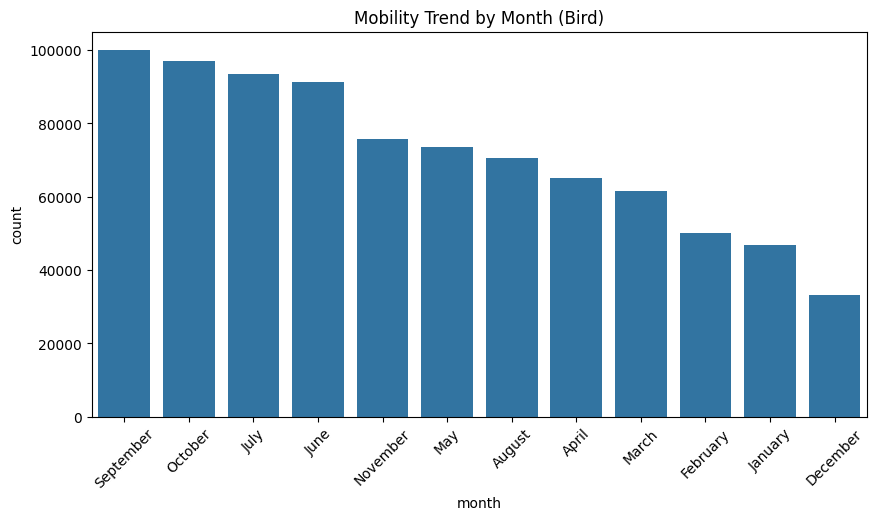

In [14]:
# 2. Mobility Trends (Weeks, Months) 
# استخراج فاکتورهای زمانی
df_bird['month'] = df_bird['start_datetime'].dt.month_name()
df_bird['week'] = df_bird['start_datetime'].dt.isocalendar().week
df_bird['hour'] = df_bird['start_datetime'].dt.hour
df_bird['day_of_week'] = df_bird['start_datetime'].dt.day_name()

# رسم نمودار روند ماهانه (Monthly Trend)
plt.figure(figsize=(10, 5))
sns.countplot(data=df_bird, x='month', order=df_bird['month'].value_counts().index)
plt.title('Mobility Trend by Month (Bird)')
plt.xticks(rotation=45)
plt.show()

Total unique vehicles: 2823
Most used vehicle ID: FITND (1031 trips)


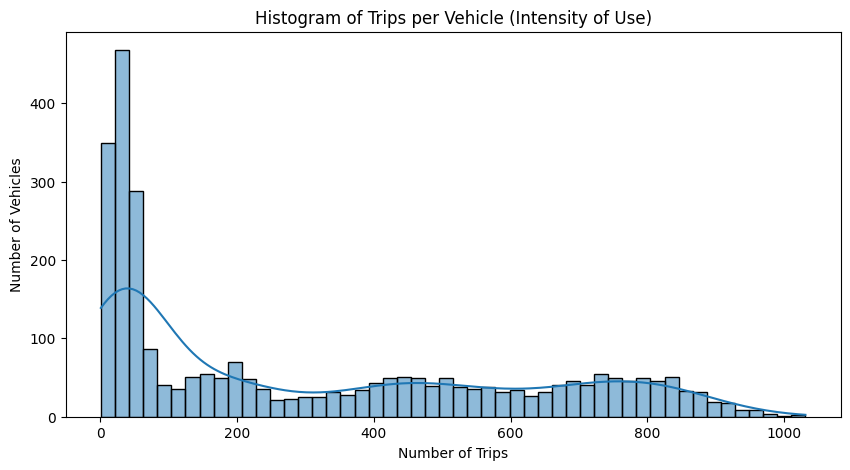

In [15]:
# 3. Vehicle Usage Analysis 
# تعداد سفر برای هر اسکوتر خاص
vehicle_trip_counts = df_bird['vehicle_id'].value_counts()

print(f"Total unique vehicles: {len(vehicle_trip_counts)}")
print(f"Most used vehicle ID: {vehicle_trip_counts.idxmax()} ({vehicle_trip_counts.max()} trips)")

# رسم هیستوگرام تعداد سفرها (Histogram of trips per vehicle) [cite: 37]
plt.figure(figsize=(10, 5))
sns.histplot(vehicle_trip_counts, bins=50, kde=True)
plt.title('Histogram of Trips per Vehicle (Intensity of Use)')
plt.xlabel('Number of Trips')
plt.ylabel('Number of Vehicles')
plt.show()

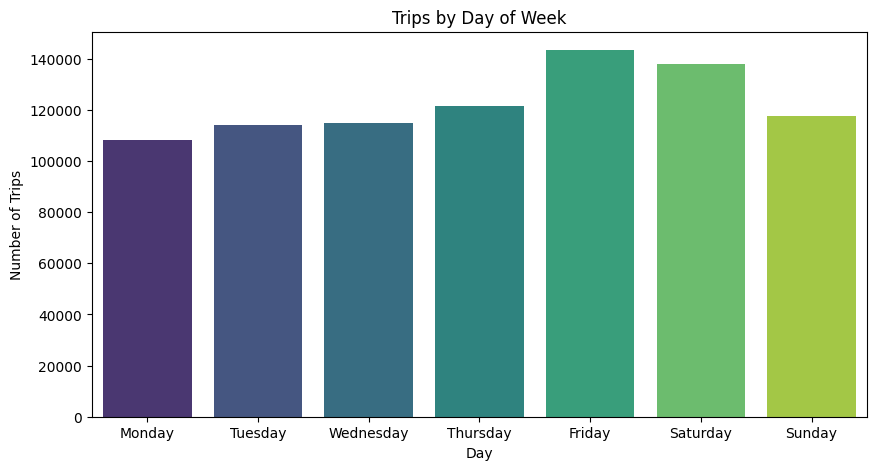

In [16]:
# 1. Day of Week Analysis (Corrected)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 5))
# تغییر: اضافه کردن hue و legend=False
sns.countplot(data=df_bird, x='day_of_week', order=days_order, hue='day_of_week', legend=False, palette='viridis')
plt.title('Trips by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Trips')
plt.show()

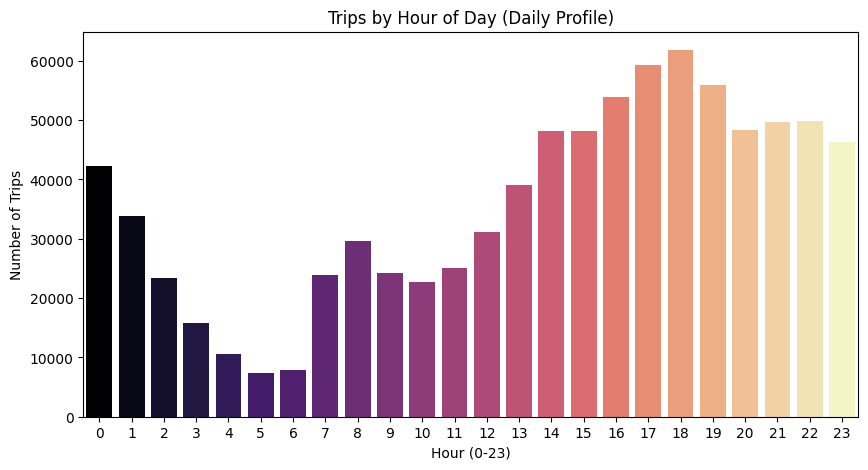

In [17]:
# 2. Hourly Analysis 
plt.figure(figsize=(10, 5))
# تغییر: اضافه کردن hue و legend=False
sns.countplot(data=df_bird, x='hour', hue='hour', legend=False, palette='magma')
plt.title('Trips by Hour of Day (Daily Profile)')
plt.xlabel('Hour (0-23)')
plt.ylabel('Number of Trips')
plt.show()

In [18]:
# 3. Descriptive Statistics (Summary Table)
stats_summary = df_bird[['distance_km', 'duration_min']].describe().round(2)

print("--- Descriptive Statistics ---")
print(stats_summary)

avg_dur = df_bird['duration_min'].mean()
avg_dist = df_bird['distance_km'].mean()
print(f"\nQuick Insight: The average trip is {avg_dur:.1f} minutes long and covers {avg_dist:.1f} km.")

--- Descriptive Statistics ---
       distance_km  duration_min
count    857957.00     857957.00
mean          3.60         13.79
std           2.48          9.92
min           0.01          0.07
25%           1.70          6.48
50%           3.10         11.62
75%           5.09         19.28
max          44.10        184.98

Quick Insight: The average trip is 13.8 minutes long and covers 3.6 km.


In [19]:
!pip install geopandas shapely

In [20]:
import geopandas as gpd
from shapely.geometry import Point

In [21]:
# 1. Setup File Path
# Using the specific path provided for your local machine
shapefile_path = "/Users/amirhosseinghaderi/Desktop/Third Semester/Post Carbon/zone_statistiche_geo/zone_statistiche_geo.shp"

try:
    # Load the Shapefile
    gdf_zones = gpd.read_file(shapefile_path)
    print("Shapefile loaded successfully!")
except Exception as e:
    print(f"Error loading Shapefile: {e}")

Shapefile loaded successfully!


In [22]:
# 2. Inspect Columns to Find Zone Name
# IMPORTANT: Look at the output of this section.
# You need to find the column that contains the Zone Name (e.g., 'DENOM', 'ZONA', 'NOME').
print("--- Shapefile Columns ---")
print(gdf_zones.columns)
print("-" * 30)
print("--- First 5 Rows ---")
print(gdf_zones.head())
print("-" * 30)

--- Shapefile Columns ---
Index(['ZONASTAT', 'DENOM', 'geometry'], dtype='object')
------------------------------
--- First 5 Rows ---
  ZONASTAT                                        DENOM  \
0       70                                    Pilonetto   
1       42                             Borgata Vittoria   
2       55                            Ospizio di Carità   
3       06                       Piazza Vittorio Veneto   
4       09  Piazza Madama Cristina (Borgo San Salvario)   

                                            geometry  
0  POLYGON ((1395895.985 4988060.107, 1395898.044...  
1  POLYGON ((1395519.219 4994610.663, 1395528.682...  
2  POLYGON ((1392498.38 4988368.989, 1392593.575 ...  
3  POLYGON ((1396903.882 4991059.344, 1396929.822...  
4  POLYGON ((1395852.47 4990177.979, 1395864.654 ...  
------------------------------


In [23]:
# 3. Convert Trip Data to GeoDataFrame
# Ensure the coordinate system matches the shapefile
target_crs = gdf_zones.crs
print(f"Shapefile CRS: {target_crs}")

# Convert Start Points
geometry_start = [Point(xy) for xy in zip(df_bird['start_longitude'], df_bird['start_latitude'])]
gdf_start = gpd.GeoDataFrame(df_bird, geometry=geometry_start, crs="EPSG:4326")
gdf_start = gdf_start.to_crs(target_crs)

# Convert End Points
geometry_end = [Point(xy) for xy in zip(df_bird['end_longitude'], df_bird['end_latitude'])]
gdf_end = gpd.GeoDataFrame(df_bird, geometry=geometry_end, crs="EPSG:4326")
gdf_end = gdf_end.to_crs(target_crs)

Shapefile CRS: EPSG:3003


In [24]:
# 4. Spatial Join
# IMPORTANT: Update 'zone_col' below with the correct column name found in step 2.
# Defaulting to the first column, but you should change it to something like 'DENOM' or 'ZONA'.
zone_col = gdf_zones.columns[0] 
# Example: zone_col = 'DENOM' 

print(f"Using column '{zone_col}' as Zone ID for mapping.")

# Join Origin Zone
gdf_start_joined = gpd.sjoin(gdf_start, gdf_zones[[zone_col, 'geometry']], how="left", predicate="within")
df_bird['origin_zone'] = gdf_start_joined[zone_col]

# Join Destination Zone
gdf_end_joined = gpd.sjoin(gdf_end, gdf_zones[[zone_col, 'geometry']], how="left", predicate="within")
df_bird['dest_zone'] = gdf_end_joined[zone_col]

# Remove trips that fall outside the defined zones (NaN values)
df_bird_clean_zones = df_bird.dropna(subset=['origin_zone', 'dest_zone'])
print(f"Trips with valid zones: {len(df_bird_clean_zones)} (Original: {len(df_bird)})")

Using column 'ZONASTAT' as Zone ID for mapping.
Trips with valid zones: 828172 (Original: 857957)


In [25]:
# 5. Create Final O-D Matrix
od_matrix_official = df_bird_clean_zones.pivot_table(
    index='origin_zone', 
    columns='dest_zone', 
    values='vehicle_id', 
    aggfunc='count', 
    fill_value=0
)

print("O-D Matrix Created Successfully!")
print(f"Matrix Dimensions: {od_matrix_official.shape}")

# Show a preview (first 5 rows and columns)
print(od_matrix_official.iloc[:5, :5])

O-D Matrix Created Successfully!
Matrix Dimensions: (83, 86)
dest_zone      01   02    03    04    05
origin_zone                             
01           1423  137   685   893   790
02            165  160   163   135    70
03            698  142  1581  1338   455
04           1237  135  1795  3266   543
05            808   86   460   477  1462


In [26]:
print(gdf_zones.head())

  ZONASTAT                                        DENOM  \
0       70                                    Pilonetto   
1       42                             Borgata Vittoria   
2       55                            Ospizio di Carità   
3       06                       Piazza Vittorio Veneto   
4       09  Piazza Madama Cristina (Borgo San Salvario)   

                                            geometry  
0  POLYGON ((1395895.985 4988060.107, 1395898.044...  
1  POLYGON ((1395519.219 4994610.663, 1395528.682...  
2  POLYGON ((1392498.38 4988368.989, 1392593.575 ...  
3  POLYGON ((1396903.882 4991059.344, 1396929.822...  
4  POLYGON ((1395852.47 4990177.979, 1395864.654 ...  


In [27]:
# --- EXERCISE 2: Final O-D Matrix & Visualization ---

# 1. Set the correct column name found by you
zone_col = 'DENOM'
print(f"Generating O-D Matrix using zone names from: {zone_col}")

Generating O-D Matrix using zone names from: DENOM


In [28]:
# 2. Re-run Spatial Join with the correct column names
# (We do this to ensure the dataframe has the names, not IDs)
gdf_start_joined = gpd.sjoin(gdf_start, gdf_zones[[zone_col, 'geometry']], how="left", predicate="within")
df_bird['origin_zone'] = gdf_start_joined[zone_col]

gdf_end_joined = gpd.sjoin(gdf_end, gdf_zones[[zone_col, 'geometry']], how="left", predicate="within")
df_bird['dest_zone'] = gdf_end_joined[zone_col]

# Remove invalid trips (outside Turin boundaries)
df_bird_clean_zones = df_bird.dropna(subset=['origin_zone', 'dest_zone'])

In [29]:
# 3. Create the Official O-D Matrix
od_matrix_final = df_bird_clean_zones.pivot_table(
    index='origin_zone', 
    columns='dest_zone', 
    values='vehicle_id', 
    aggfunc='count', 
    fill_value=0
)
print(f"Final Matrix Shape: {od_matrix_final.shape}")
print("Top 5 Origin Zones:")
print(od_matrix_final.index[:5])

# --- VISUALIZATION (MAP) ---

Final Matrix Shape: (83, 86)
Top 5 Origin Zones:
Index(['Aeronautica - Pellerina', 'Barca - Bertolla - Abbadia di Stura',
       'Barriera di Chieri - Valpiana - Val San Martino',
       'Barriera di Orbassano', 'Barriera di Stura - Istituto Rebaudengo'],
      dtype='object', name='origin_zone')


In [30]:
# 4. Prepare Data for Mapping
# Count trips starting from each zone
trips_per_zone = df_bird_clean_zones['origin_zone'].value_counts().reset_index()
trips_per_zone.columns = [zone_col, 'trip_count']

# Merge trip counts back to the Shapefile for plotting
gdf_mapping = gdf_zones.merge(trips_per_zone, on=zone_col, how='left')
# Fill zones with 0 trips
gdf_mapping['trip_count'] = gdf_mapping['trip_count'].fillna(0)

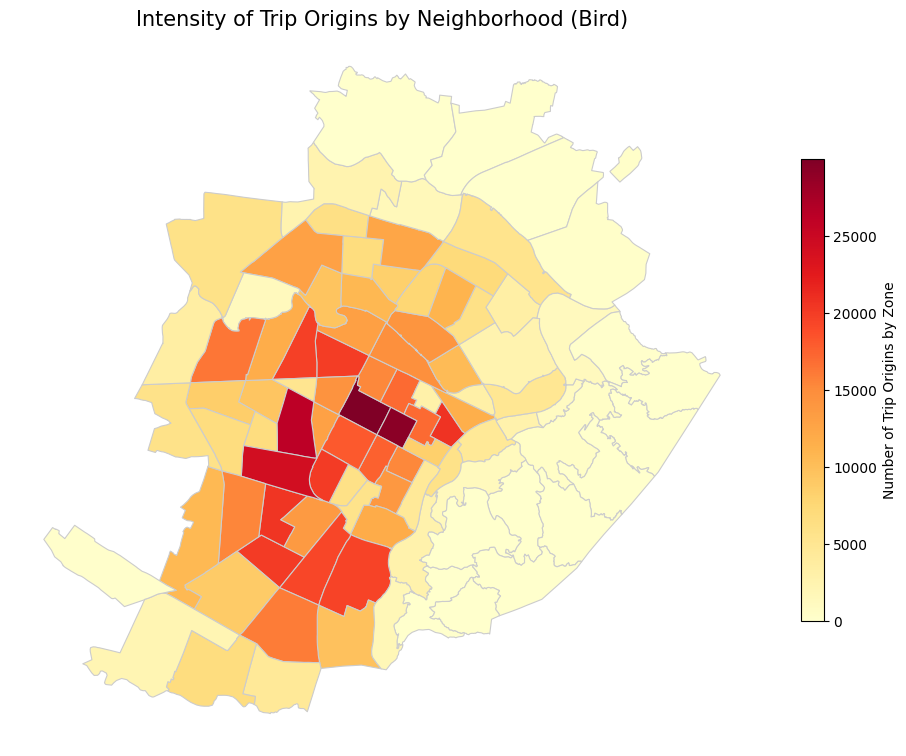

In [31]:
# 5. Plot the Map (Choropleth)
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

gdf_mapping.plot(
    column='trip_count',
    cmap='YlOrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Number of Trip Origins by Zone" ,'shrink': 0.6},
    ax=ax
)

ax.set_title('Intensity of Trip Origins by Neighborhood (Bird)', fontsize=15)
ax.set_axis_off() # Remove axis for a cleaner look
plt.show()

In [32]:
# 1. Define Peak Hours based on Exercise 1 findings
# We observed a major peak in the afternoon (16:00 - 19:00)
peak_hours = [16, 17, 18, 19]

# Create a filter for peak and off-peak
df_bird['is_peak'] = df_bird['hour'].isin(peak_hours)

In [33]:
 # 2. Create O-D Matrices for Peak vs Off-Peak
# Peak Matrix
od_matrix_peak = df_bird[df_bird['is_peak']].pivot_table(
    index='origin_zone', 
    columns='dest_zone', 
    values='vehicle_id', 
    aggfunc='count', 
    fill_value=0
)

# Off-Peak Matrix
od_matrix_offpeak = df_bird[~df_bird['is_peak']].pivot_table(
    index='origin_zone', 
    columns='dest_zone', 
    values='vehicle_id', 
    aggfunc='count', 
    fill_value=0
)

print(f"Peak Matrix Shape: {od_matrix_peak.shape}")
print(f"Off-Peak Matrix Shape: {od_matrix_offpeak.shape}")

Peak Matrix Shape: (83, 84)
Off-Peak Matrix Shape: (83, 86)


In [34]:
# 3.Generators vs. Attractors (Net Flow)
# Concept: 
# If a zone has more 'Ends' than 'Starts', it attracts people (e.g., City Center/Mall).
# If a zone has more 'Starts' than 'Ends', it generates trips (e.g., Residential areas).

# Count starts and ends per zone
starts_per_zone = df_bird['origin_zone'].value_counts()
ends_per_zone = df_bird['dest_zone'].value_counts()

# Create a DataFrame for flow analysis
flow_df = pd.DataFrame({'Starts': starts_per_zone, 'Ends': ends_per_zone}).fillna(0)
flow_df['Net_Flow'] = flow_df['Ends'] - flow_df['Starts']

# Identify top Attractors (Positive Net Flow) and Generators (Negative Net Flow)
top_attractors = flow_df.sort_values(by='Net_Flow', ascending=False).head(5)
top_generators = flow_df.sort_values(by='Net_Flow', ascending=True).head(5)

print("\n--- Top 5 Attractor Zones (More arrivals) ---")
print(top_attractors)
print("\n--- Top 5 Generator Zones (More departures) ---")
print(top_generators)


--- Top 5 Attractor Zones (More arrivals) ---
                          Starts   Ends  Net_Flow
Venchi Unica              6406.0   7803    1397.0
Vecchia Piazza D'Armi    18130.0  19418    1288.0
Borgo San Donato         20070.0  21010     940.0
Drosso - Fornaci          2435.0   3330     895.0
Aeronautica - Pellerina   3845.0   4692     847.0

--- Top 5 Generator Zones (More departures) ---
                                         Starts   Ends  Net_Flow
Piazza San Carlo - Piazza Carlo Felice  29413.0  23465   -5948.0
Piazza Vittorio Veneto                  20895.0  15987   -4908.0
Comandi Militari - Stazione Porta Susa  30144.0  25462   -4682.0
Stadio Comunale                         13860.0  10992   -2868.0
Borgata Campidoglio - Martinetto        20122.0  17724   -2398.0


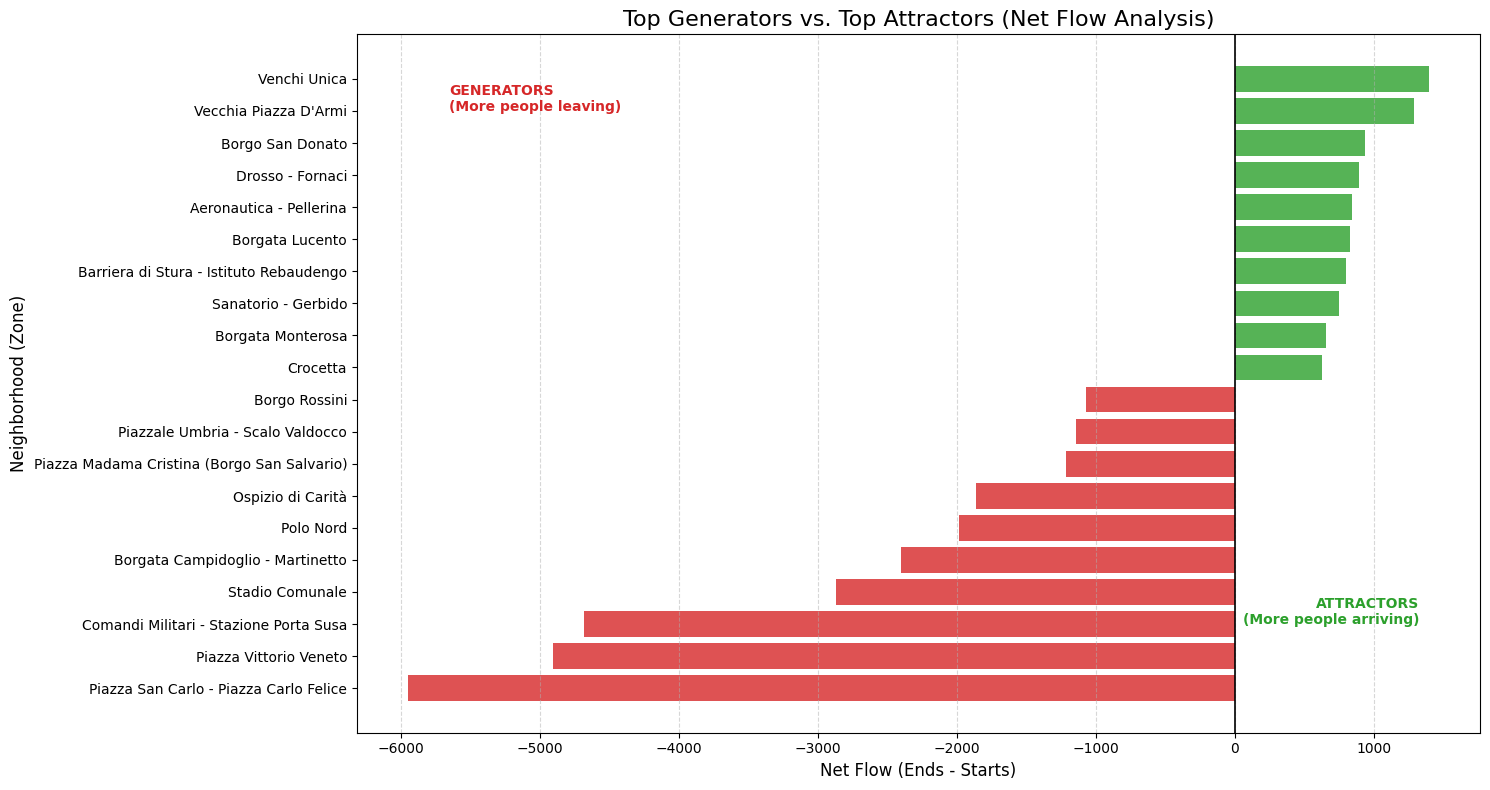

In [35]:
# 1. Filter out zones with very low activity to avoid noise
# Only consider zones that had at least 50 trips in total
active_zones = flow_df[flow_df['Starts'] + flow_df['Ends'] > 50].copy()

# 2. Select the Extremes (Top 10 Attractors and Top 10 Generators)
# Top 10 Zones with positive Net Flow (More Arrivals)
top_attractors = active_zones.sort_values('Net_Flow', ascending=False).head(10)

# Top 10 Zones with negative Net Flow (More Departures)
top_generators = active_zones.sort_values('Net_Flow', ascending=True).head(10)

# Combine them into one DataFrame for plotting
comparison_df = pd.concat([top_attractors, top_generators]).sort_values('Net_Flow')

# 3. Create Color Logic
# Green for Positive (Attractor), Red for Negative (Generator)
colors = ['#d62728' if x < 0 else '#2ca02c' for x in comparison_df['Net_Flow']]

# 4. Plot Horizontal Bar Chart
plt.figure(figsize=(15, 8))

# Create the bars
bars = plt.barh(comparison_df.index, comparison_df['Net_Flow'], color=colors, alpha=0.8)

# Add a vertical line at zero
plt.axvline(0, color='black', linewidth=1.2, linestyle='-')

# Add grid for easier reading
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add Labels and Titles
plt.title('Top Generators vs. Top Attractors (Net Flow Analysis)', fontsize=16)
plt.xlabel('Net Flow (Ends - Starts)', fontsize=12)
plt.ylabel('Neighborhood (Zone)', fontsize=12)

# 5. Add Annotations (Arrows and Text) to make it "Self-Explanatory"
# Text for Generators (Left side)
plt.text(x=comparison_df['Net_Flow'].min() * 0.95, y=len(comparison_df)-2, 
         s="GENERATORS\n(More people leaving)", 
         color='#d62728', fontweight='bold', ha='left', fontsize=10)

# Text for Attractors (Right side)
plt.text(x=comparison_df['Net_Flow'].max() * 0.95, y=2, 
         s="ATTRACTORS\n(More people arriving)", 
         color='#2ca02c', fontweight='bold', ha='right', fontsize=10)

plt.tight_layout()
plt.show()

In [36]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString
import matplotlib.pyplot as plt
import os

# --- EXERCISE 3

# 1. load
base_folder = "/Users/amirhosseinghaderi/Desktop/Third Semester/Transport/Projects/EX1/metro and bus"

metro_path = os.path.join(base_folder, "linee_metro_geo.shp")
stops_path = os.path.join(base_folder, "stops.txt")
shapes_path = os.path.join(base_folder, "shapes.txt")

print(f"📂 Reading files from: {base_folder}")

# 2. Load Metro Line
try:
    if os.path.exists(metro_path):
        gdf_metro = gpd.read_file(metro_path)
        if gdf_metro.crs != "EPSG:4326":
            gdf_metro = gdf_metro.to_crs("EPSG:4326")
        print("✅ Metro line loaded successfully!")
    else:
        print(f"❌ Metro file not found at: {metro_path}")
        gdf_metro = None
except Exception as e:
    print(f"❌ Error loading Metro: {e}")
    gdf_metro = None

# 3. Load Bus Stops (stops.txt)
try:
    if os.path.exists(stops_path):
        stops_df = pd.read_csv(stops_path)
        # تبدیل به فرمت مکانی
        geometry_stops = [Point(xy) for xy in zip(stops_df['stop_lon'], stops_df['stop_lat'])]
        gdf_stops = gpd.GeoDataFrame(stops_df, geometry=geometry_stops, crs="EPSG:4326")
        print(f"✅ Loaded {len(gdf_stops)} bus/tram stops.")
    else:
        print(f"❌ stops.txt not found at: {stops_path}")
        gdf_stops = gpd.GeoDataFrame()
except Exception as e:
    print(f"❌ Error loading stops.txt: {e}")
    gdf_stops = gpd.GeoDataFrame()

# 4. Load Bus Routes (shapes.txt)
try:
    if os.path.exists(shapes_path):
        print("⏳ Processing ALL bus routes... (this might take 10-20 seconds)")
        shapes_df = pd.read_csv(shapes_path)

        # Function to create lines (Optimized)
        def make_line(group):
            if len(group) > 1:
                # مرتب‌سازی نقاط برای اینکه خط کج و کوله نشود
                group = group.sort_values('shape_pt_sequence')
                return LineString(zip(group['shape_pt_lon'], group['shape_pt_lat']))
            else:
                return None

        gdf_bus_lines = shapes_df.groupby('shape_id')[['shape_pt_lon', 'shape_pt_lat', 'shape_pt_sequence']].apply(make_line).reset_index()
        
        gdf_bus_lines.columns = ['shape_id', 'geometry']
        gdf_bus_lines = gpd.GeoDataFrame(gdf_bus_lines.dropna(), geometry='geometry', crs="EPSG:4326")
        
        print(f"✅ Successfully processed ALL {len(gdf_bus_lines)} bus route geometries.")
    else:
        print(f"⚠️ shapes.txt not found at: {shapes_path}")
        gdf_bus_lines = gpd.GeoDataFrame()

except Exception as e:
    print(f"⚠️ Warning processing shapes.txt: {e}")
    gdf_bus_lines = gpd.GeoDataFrame()

📂 Reading files from: /Users/amirhosseinghaderi/Desktop/Third Semester/Transport/Projects/EX1/metro and bus
✅ Metro line loaded successfully!
✅ Loaded 7049 bus/tram stops.
⏳ Processing ALL bus routes... (this might take 10-20 seconds)
✅ Successfully processed ALL 1461 bus route geometries.


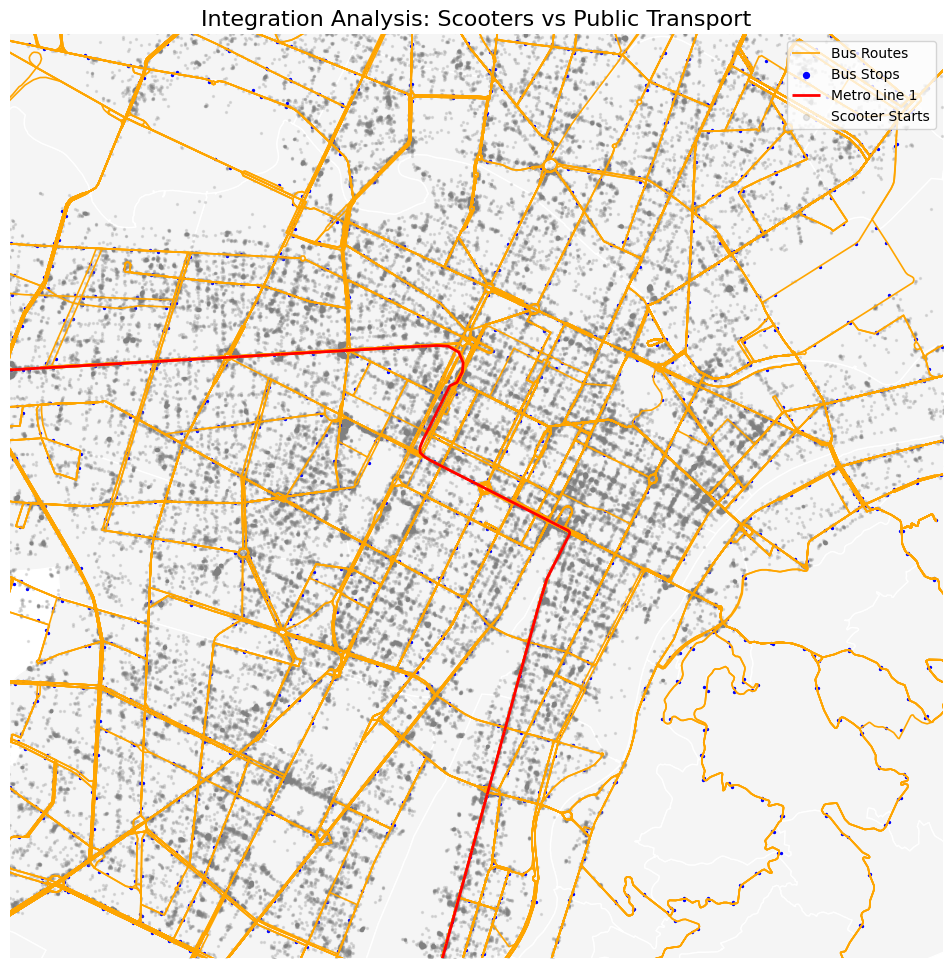

In [37]:
# 5. VISUALIZATION
if gdf_metro is not None or not gdf_stops.empty:
    
    if 'df_bird' in locals():
        df_sample = df_bird[df_bird['month'] == 'September'].copy()
    else:
        df_sample = pd.DataFrame() 

    fig, ax = plt.subplots(figsize=(15, 12))

    # Layer A: City Zones (Background)
    if 'gdf_zones' in locals():
        gdf_zones.to_crs("EPSG:4326").plot(ax=ax, color='#f5f5f5', edgecolor='white')

    # Layer B: Bus Routes
    if not gdf_bus_lines.empty:
        gdf_bus_lines.plot(ax=ax, color='orange', linewidth=1.2, alpha=1, label='Bus Routes')

    # Layer C: Bus Stops
    if not gdf_stops.empty:
        gdf_stops.plot(ax=ax, color='blue', markersize=2, alpha=1, label='Bus Stops')

    # Layer D: Metro Line
    if gdf_metro is not None:
        gdf_metro.plot(ax=ax, color='red', linewidth=2, alpha=1, label='Metro Line 1', zorder=5)

    # # Layer E: Scooter Starts
    if not df_sample.empty:
        ax.scatter(df_sample['start_longitude'], df_sample['start_latitude'],
                   c='gray', s=2, alpha=0.2, label='Scooter Starts')

    plt.title('Integration Analysis: Scooters vs Public Transport', fontsize=16)
    plt.legend(loc='upper right', markerscale=3)
    
    # Zoom on Turin Center
    ax.set_xlim(7.62, 7.72)
    ax.set_ylim(45.03, 45.10)
    ax.set_axis_off()
    
    plt.show()
else:
    print("❌ Public transport data failed to load. Please check file names in the folder.")

🔍 Starting Advanced Analysis with Metric Projection (EPSG:32632)...
   Creating 300m buffer around Metro line...
   Converting scooter points to metric system...
   Checking spatial intersection...
Total Trips Analyzed (Sept): 100045
🔴 Direct Competitors (Substitutes): 5761 (5.8%)
🟢 First/Last Mile Connectors (Feeders): 27132 (27.1%)
⚪ Independent Trips (No Metro Connection): 67152 (67.1%)


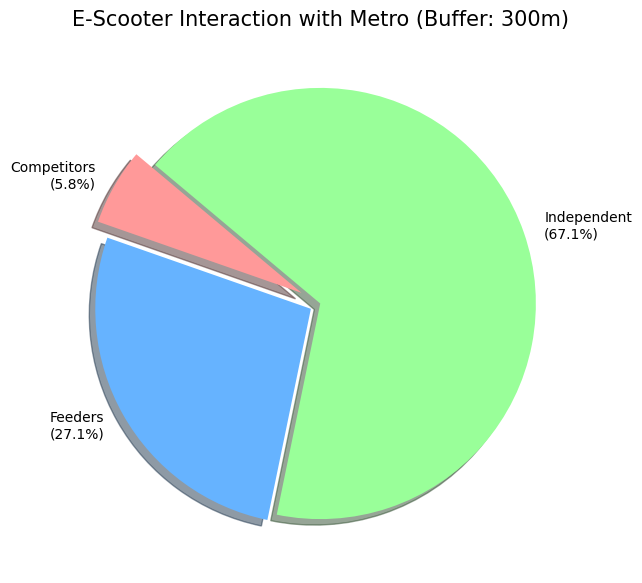

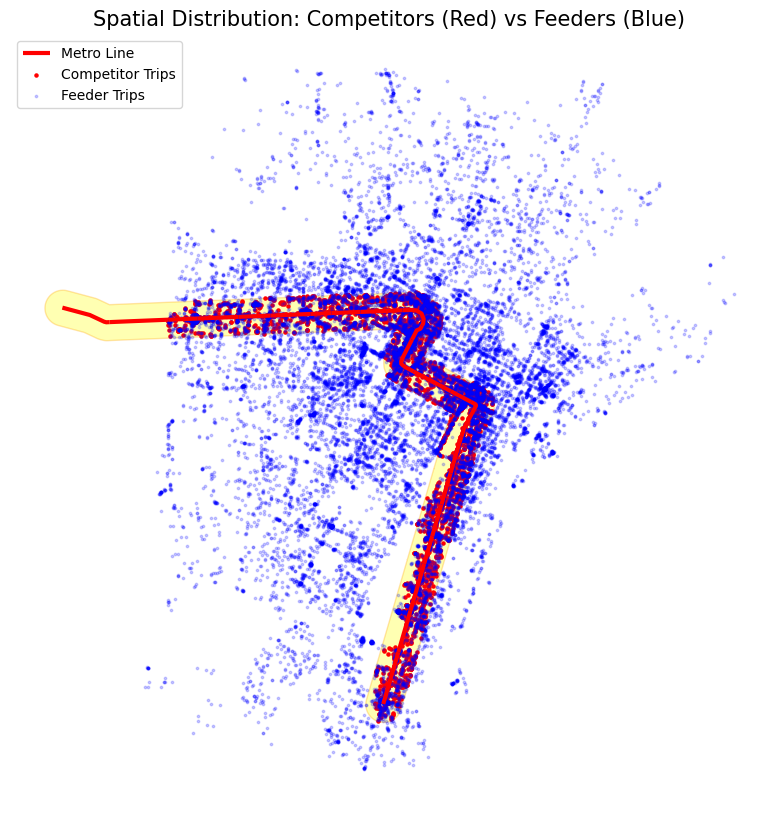

In [38]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --- BONUS EXERCISE 3 (FIXED): Metric Projection Analysis ---

print("🔍 Starting Advanced Analysis with Metric Projection (EPSG:32632)...")

if gdf_metro is not None and 'df_sample' in locals():
    
    # 1. Reproject Metro to Meters (UTM Zone 32N - Standard for Italy)
    # This allows us to define the buffer in METERS, not degrees.
    gdf_metro_metric = gdf_metro.to_crs("EPSG:32632")
    
    # Define buffer distance: 300 meters
    BUFFER_METERS = 300
    
    # Create the buffer (using union_all to fix the deprecation warning)
    print(f"   Creating {BUFFER_METERS}m buffer around Metro line...")
    metro_buffer_metric = gdf_metro_metric.geometry.buffer(BUFFER_METERS).union_all()
    
    # 2. Convert Scooter Points to GeoDataFrame and Reproject to Meters
    print("   Converting scooter points to metric system...")
    
    # Start Points
    gdf_start = gpd.GeoDataFrame(
        df_sample, 
        geometry=gpd.points_from_xy(df_sample['start_longitude'], df_sample['start_latitude']),
        crs="EPSG:4326"
    ).to_crs("EPSG:32632")
    
    # End Points
    gdf_end = gpd.GeoDataFrame(
        df_sample, 
        geometry=gpd.points_from_xy(df_sample['end_longitude'], df_sample['end_latitude']),
        crs="EPSG:4326"
    ).to_crs("EPSG:32632")
    
    # 3. Perform Spatial Check (Is point within buffer?)
    print("   Checking spatial intersection...")
    df_sample['start_near_metro'] = gdf_start.geometry.within(metro_buffer_metric)
    df_sample['end_near_metro'] = gdf_end.geometry.within(metro_buffer_metric)
    
    # 4. Classify Trips
    # COMPETITOR: Both Start AND End are near Metro
    competitors = df_sample[df_sample['start_near_metro'] & df_sample['end_near_metro']]
    
    # FEEDER: Only ONE end is near Metro (Start OR End, but not both)
    # XOR operator (^) returns True if only one is True
    feeders = df_sample[df_sample['start_near_metro'] ^ df_sample['end_near_metro']]
    
    # OTHER: Neither
    others = df_sample[~(df_sample['start_near_metro'] | df_sample['end_near_metro'])]
    
    # 5. Calculate Percentages
    total_trips = len(df_sample)
    comp_pct = (len(competitors) / total_trips) * 100
    feed_pct = (len(feeders) / total_trips) * 100
    other_pct = (len(others) / total_trips) * 100
    
    print("="*50)
    print(f"Total Trips Analyzed (Sept): {total_trips}")
    print(f"🔴 Direct Competitors (Substitutes): {len(competitors)} ({comp_pct:.1f}%)")
    print(f"🟢 First/Last Mile Connectors (Feeders): {len(feeders)} ({feed_pct:.1f}%)")
    print(f"⚪ Independent Trips (No Metro Connection): {len(others)} ({other_pct:.1f}%)")
    print("="*50)
    
    # 6. VISUALIZATION: Pie Chart
    labels = [f'Competitors\n({comp_pct:.1f}%)', f'Feeders\n({feed_pct:.1f}%)', f'Independent\n({other_pct:.1f}%)']
    sizes = [len(competitors), len(feeders), len(others)]
    colors = ['#ff9999', '#66b3ff', '#99ff99'] # Red, Blue, Green
    explode = (0.1, 0.05, 0)

    plt.figure(figsize=(12, 7))
    plt.pie(sizes, explode=explode, labels=labels, colors=colors, shadow=True, startangle=140)
    plt.title(f'E-Scooter Interaction with Metro (Buffer: {BUFFER_METERS}m)', fontsize=15)
    plt.show()

    # 7. MAP: Visualizing Competitors vs Feeders
    # Let's plot a zoom of the center to see the points
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot Buffer Area
    gpd.GeoSeries([metro_buffer_metric], crs="EPSG:32632").plot(ax=ax, color='yellow', alpha=0.3, edgecolor='orange')
    
    # Plot Metro Line
    gdf_metro_metric.plot(ax=ax, color='red', linewidth=3, label='Metro Line', zorder=5)
    
    # Plot Competitors (Red Points) - Converting back to metric for plot consistency if needed, 
    # but simplest is to plot the calculated gdf_start subset
    gdf_comp_start = gdf_start[df_sample['start_near_metro'] & df_sample['end_near_metro']]
    gdf_comp_start.plot(ax=ax, color='red', markersize=5, label='Competitor Trips', alpha=1)
    
    # Plot Feeders (Blue Points)
    gdf_feed_start = gdf_start[df_sample['start_near_metro'] ^ df_sample['end_near_metro']]
    gdf_feed_start.plot(ax=ax, color='blue', markersize=3, label='Feeder Trips', alpha=0.2)

    plt.title('Spatial Distribution: Competitors (Red) vs Feeders (Blue)', fontsize=15)
    plt.legend()
    ax.set_axis_off()
    
    # Zoom in (coordinates are now in METERS, usually large numbers like 395000, 4990000)
    # We let matplotlib auto-scale to the data
    
    plt.show()

else:
    print("❌ Data missing. Please run previous steps first.")

⏳ Calculating parking durations... (this might take a moment)
✅ Calculated 854100 parking events.
📊 Overall Average Parking Duration: 18.73 hours


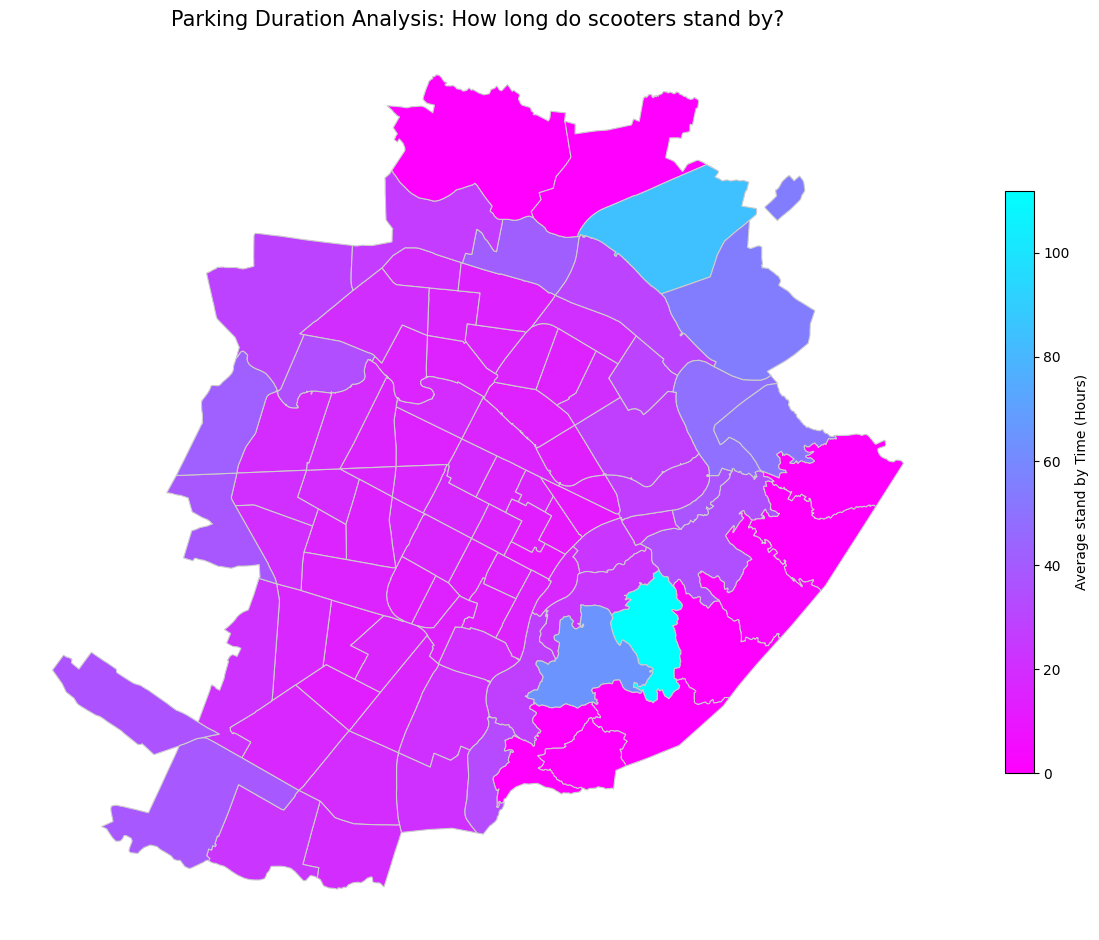

🗺️ Map generated! Blue areas = High Demand (Low Parking Time).


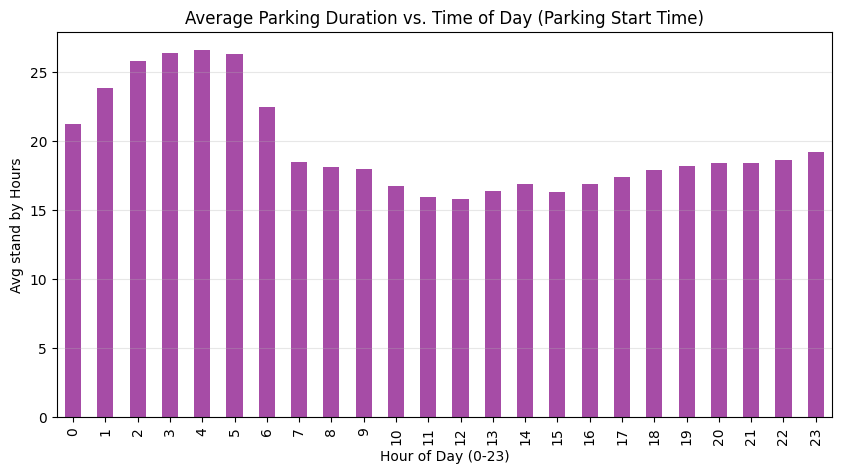

In [39]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --- EXERCISE 4: PARKING DURATION ANALYSIS ---

print("⏳ Calculating parking durations... (this might take a moment)")

# 1. Sort Data to Calculate stand by Time
# We must look at each vehicle's timeline separately
df_bird = df_bird.sort_values(by=['vehicle_id', 'start_datetime'])

# 2. Calculate "Next Trip Start Time"
# Shift the start_datetime back by 1 position for each vehicle
df_bird['next_start_time'] = df_bird.groupby('vehicle_id')['start_datetime'].shift(-1)

# 3. Calculate Duration
# Formula: Next Start - Current End
df_bird['parking_duration_hours'] = (df_bird['next_start_time'] - df_bird['end_datetime']).dt.total_seconds() / 3600

# 4. Filter Valid Parkings
# Remove negative values (data errors) and extremely long parkings (> 30 days = lost/broken)
df_parking = df_bird[
    (df_bird['parking_duration_hours'] >= 0) & 
    (df_bird['parking_duration_hours'] < 720) # Max 30 days
].copy()

print(f"✅ Calculated {len(df_parking)} parking events.")
print(f"📊 Overall Average Parking Duration: {df_parking['parking_duration_hours'].mean():.2f} hours")

# 5. Aggregate by Zone (Where the scooter was parked)
# IMPORTANT: The parking happens at the DESTINATION of the trip.
zone_col = 'DENOM'  # Using the column name we found earlier
avg_parking_zone = df_parking.groupby('dest_zone')['parking_duration_hours'].mean().reset_index()
avg_parking_zone.columns = [zone_col, 'avg_parking_hours']

# 6. VISUALIZATION: Choropleth Map
# Merge with Shapefile
if 'gdf_zones' in locals():
    gdf_parking_map = gdf_zones.merge(avg_parking_zone, on=zone_col, how='left')
    
    # Fill NaN with 0 or drop them
    gdf_parking_map['avg_parking_hours'] = gdf_parking_map['avg_parking_hours'].fillna(0)

    fig, ax = plt.subplots(1, 1, figsize=(12, 10))

    gdf_parking_map.plot(
        column='avg_parking_hours',
        cmap='cool_r',      # 'cool_r' (Reverse Cool) -> Blue=Short (Good), Pink=Long (Bad)
        linewidth=0.8,
        edgecolor='0.8',
        legend=True,
        legend_kwds={'label': "Average stand by Time (Hours)", 'shrink': 0.6},
        missing_kwds={'color': 'lightgrey'}, 
        ax=ax
    )

    ax.set_title('Parking Duration Analysis: How long do scooters stand by?', fontsize=15)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()
    print("🗺️ Map generated! Blue areas = High Demand (Low Parking Time).")
else:
    print("❌ Shapefile (gdf_zones) not found. Cannot plot map.")

# 7. HOURLY ANALYSIS (Bonus)
# When does long parking happen?
df_parking['parking_start_hour'] = df_parking['end_datetime'].dt.hour
hourly_parking = df_parking.groupby('parking_start_hour')['parking_duration_hours'].mean()

plt.figure(figsize=(10, 5))
hourly_parking.plot(kind='bar', color='purple', alpha=0.7)
plt.title('Average Parking Duration vs. Time of Day (Parking Start Time)')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Avg stand by Hours')
plt.grid(axis='y', alpha=0.3)
plt.show()

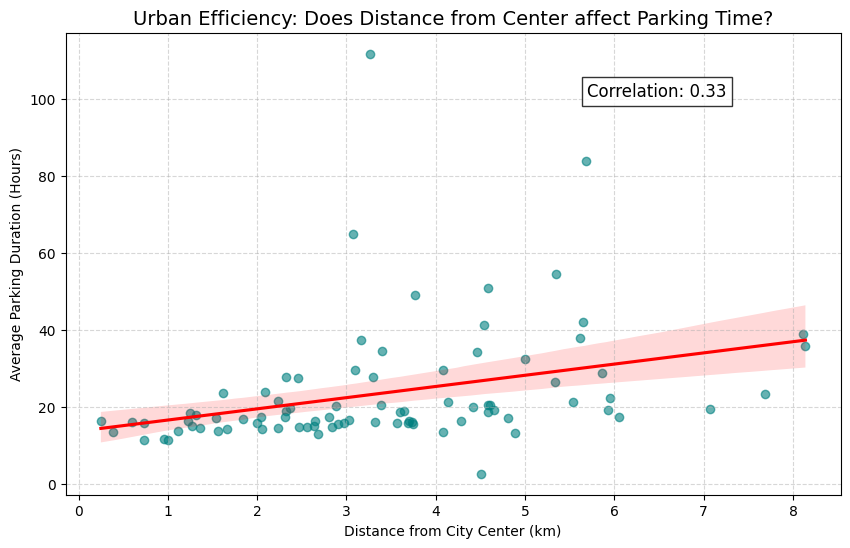

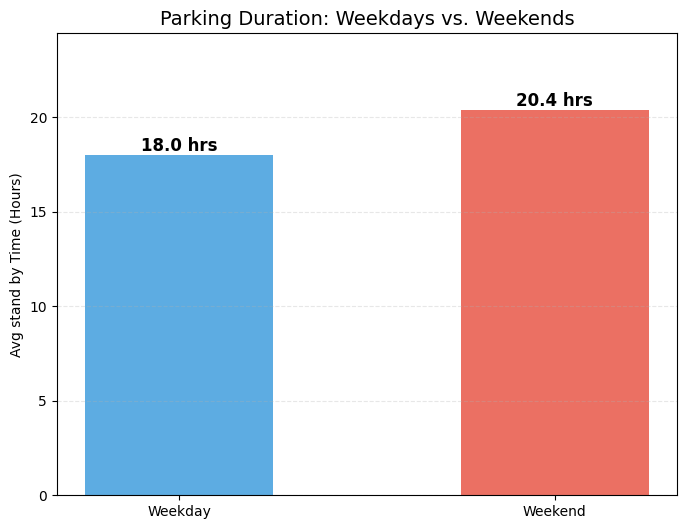

In [42]:
# Ensure df_parking exists (re-run logic if needed)
if 'df_parking' not in locals():
    # Sort and calculate if missing
    df_bird = df_bird.sort_values(by=['vehicle_id', 'start_datetime'])
    df_bird['next_start_time'] = df_bird.groupby('vehicle_id')['start_datetime'].shift(-1)
    df_bird['parking_duration_hours'] = (df_bird['next_start_time'] - df_bird['end_datetime']).dt.total_seconds() / 3600
    df_parking = df_bird[(df_bird['parking_duration_hours'] >= 0) & (df_bird['parking_duration_hours'] < 720)].copy()

# --- PART 1: The "Efficiency Curve" (Distance to Center vs. stand by Time) ---

# Define Turin Center (Piazza Castello approx coordinates)
center_point = Point(7.6869, 45.0703) # Lon, Lat

# Calculate Zone Centroids
# We need to switch to metric (EPSG:32632) to get distance in Meters/Kilometers
gdf_zones_metric = gdf_zones.to_crs("EPSG:32632")
gdf_zones_metric['centroid'] = gdf_zones_metric.geometry.centroid

# Convert center point to metric
center_series = gpd.GeoSeries([center_point], crs="EPSG:4326").to_crs("EPSG:32632")
center_metric = center_series.iloc[0]

# Calculate Distance for each zone (in Kilometers)
gdf_zones_metric['dist_to_center_km'] = gdf_zones_metric['centroid'].distance(center_metric) / 1000

# Merge Parking Data with Distance
zone_stats = df_parking.groupby('dest_zone')['parking_duration_hours'].mean().reset_index()
zone_stats.columns = [zone_col, 'avg_parking_hours']

# Combine with Zone info (Distance)
analysis_df = gdf_zones_metric[[zone_col, 'dist_to_center_km']].merge(zone_stats, on=zone_col)

# Visualization 1: Scatter Plot with Trend Line
plt.figure(figsize=(10, 6))
sns.regplot(x='dist_to_center_km', y='avg_parking_hours', data=analysis_df, 
            scatter_kws={'alpha':0.6, 'color':'teal'}, line_kws={'color':'red'})

plt.title('Urban Efficiency: Does Distance from Center affect Parking Time?', fontsize=14)
plt.xlabel('Distance from City Center (km)')
plt.ylabel('Average Parking Duration (Hours)')
plt.grid(True, linestyle='--', alpha=0.5)

# Calculate Correlation
corr = analysis_df['dist_to_center_km'].corr(analysis_df['avg_parking_hours'])
plt.text(x=analysis_df['dist_to_center_km'].max()*0.7, y=analysis_df['avg_parking_hours'].max()*0.9, 
         s=f'Correlation: {corr:.2f}', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.show()

# --- PART 2: Weekday vs. Weekend Analysis ---

# Define Weekend (Saturday=5, Sunday=6)
df_parking['day_of_week'] = df_parking['end_datetime'].dt.dayofweek
df_parking['is_weekend'] = df_parking['day_of_week'].isin([5, 6])
df_parking['day_type'] = df_parking['is_weekend'].map({True: 'Weekend', False: 'Weekday'})

# Calculate Averages
day_stats = df_parking.groupby('day_type')['parking_duration_hours'].mean()

# Visualization 2: Comparison Bar Chart
plt.figure(figsize=(8, 6))
colors = ['#3498db', '#e74c3c'] # Blue for Weekday, Red for Weekend
bars = plt.bar(day_stats.index, day_stats.values, color=colors, alpha=0.8, width=0.5)

plt.title('Parking Duration: Weekdays vs. Weekends', fontsize=14)
plt.ylabel('Avg stand by Time (Hours)')
plt.ylim(0, day_stats.max() * 1.2) # Add some space on top

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f} hrs',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

💰 Starting Financial Analysis...
--- 💵 REVENUE SUMMARY ---
Total Revenue: €3,815,400.50
Total Trips: 857957
Average Revenue per Trip (Ticket): €4.45

--- 📉 PROFITABILITY SUMMARY ---
Total Operational Cost: €1,461,156.00
Net Profit (Loss): €2,354,244.50
Is the business profitable? ✅ YES


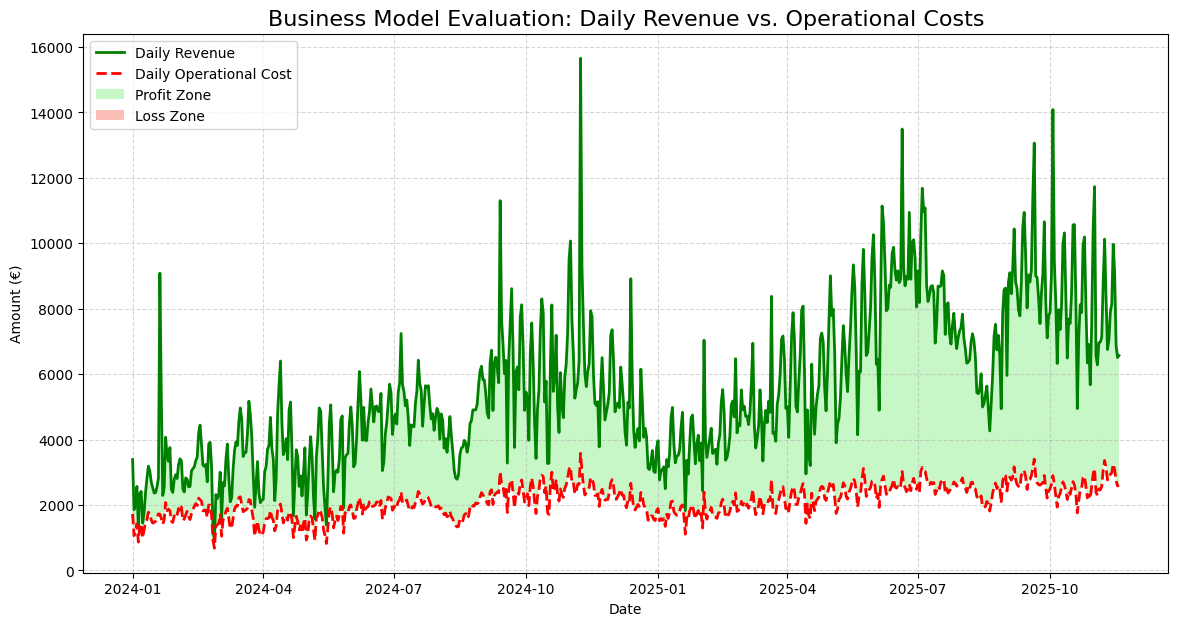

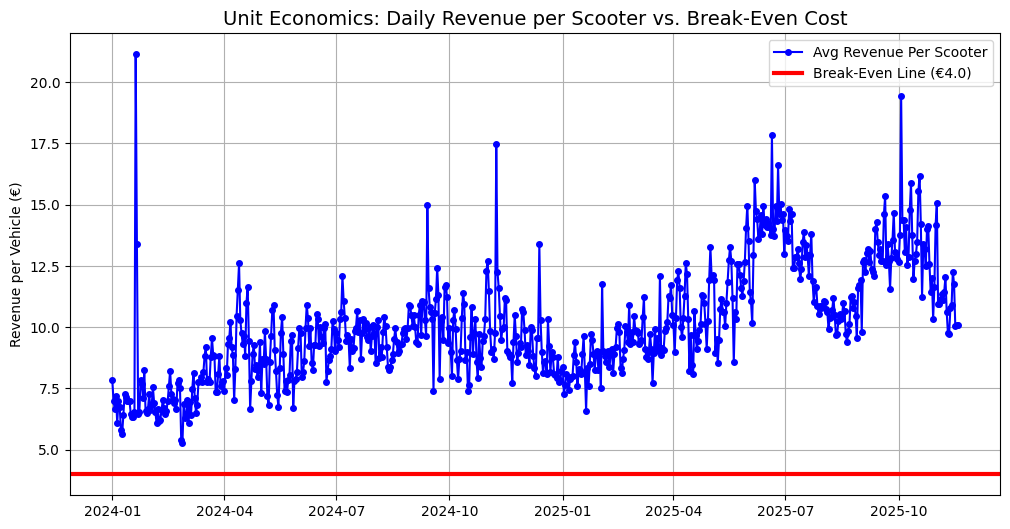

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- EXERCISE 5: BUSINESS MODEL EVALUATION ---

print("💰 Starting Financial Analysis...")

# 1. Define Pricing & Cost Assumptions (Change these if PDF says otherwise)
UNLOCK_FEE = 1.00       # Euro per trip start
MINUTE_RATE = 0.25      # Euro per minute
DAILY_OP_COST = 4.00    # Euro per scooter per day (Charging, Ops, Depreciation)

# 2. Calculate Revenue per Trip
# Ensure duration is in minutes
df_bird['duration_min'] = (df_bird['end_datetime'] - df_bird['start_datetime']).dt.total_seconds() / 60

# Formula: 1€ + (0.19€ * minutes)
df_bird['trip_revenue'] = UNLOCK_FEE + (df_bird['duration_min'] * MINUTE_RATE)

# 3. Aggregating Financials
total_revenue = df_bird['trip_revenue'].sum()
total_trips = len(df_bird)
avg_ticket = df_bird['trip_revenue'].mean()

print(f"--- 💵 REVENUE SUMMARY ---")
print(f"Total Revenue: €{total_revenue:,.2f}")
print(f"Total Trips: {total_trips}")
print(f"Average Revenue per Trip (Ticket): €{avg_ticket:.2f}")

# 4. Profitability Analysis (Daily)
# We need to calculate Revenue vs Cost per Day
df_bird['date'] = df_bird['start_datetime'].dt.date

# Daily Revenue
daily_revenue = df_bird.groupby('date')['trip_revenue'].sum()

# Daily Cost calculation:
# Cost = (Number of Active Scooters on that day) * Daily_Op_Cost
# To be precise, let's count unique vehicles active each day
daily_active_fleet = df_bird.groupby('date')['vehicle_id'].nunique()
daily_cost = daily_active_fleet * DAILY_OP_COST

# Combine into a DataFrame
finance_df = pd.DataFrame({
    'Revenue': daily_revenue,
    'Cost': daily_cost,
    'Active_Scooters': daily_active_fleet
})

finance_df['Profit'] = finance_df['Revenue'] - finance_df['Cost']
finance_df['Margin_Percent'] = (finance_df['Profit'] / finance_df['Revenue']) * 100

# Total Net Profit
total_profit = finance_df['Profit'].sum()
print(f"\n--- 📉 PROFITABILITY SUMMARY ---")
print(f"Total Operational Cost: €{finance_df['Cost'].sum():,.2f}")
print(f"Net Profit (Loss): €{total_profit:,.2f}")
print(f"Is the business profitable? {'✅ YES' if total_profit > 0 else '❌ NO'}")

# 5. VISUALIZATION: Daily Revenue vs Cost
plt.figure(figsize=(14, 7))

# Plot Revenue Line
plt.plot(finance_df.index, finance_df['Revenue'], label='Daily Revenue', color='green', linewidth=2)

# Plot Cost Line
plt.plot(finance_df.index, finance_df['Cost'], label='Daily Operational Cost', color='red', linestyle='--', linewidth=2)

# Fill area between lines to show Profit/Loss
plt.fill_between(finance_df.index, finance_df['Revenue'], finance_df['Cost'], 
                 where=(finance_df['Revenue'] >= finance_df['Cost']), 
                 facecolor='lightgreen', alpha=0.5, interpolate=True, label='Profit Zone')

plt.fill_between(finance_df.index, finance_df['Revenue'], finance_df['Cost'], 
                 where=(finance_df['Revenue'] < finance_df['Cost']), 
                 facecolor='salmon', alpha=0.5, interpolate=True, label='Loss Zone')

plt.title('Business Model Evaluation: Daily Revenue vs. Operational Costs', fontsize=16)
plt.ylabel('Amount (€)')
plt.xlabel('Date')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 6. BONUS VISUALIZATION: Break-Even Analysis (Revenue per Scooter)
# How much does EACH scooter earn per day?
finance_df['Rev_Per_Scooter'] = finance_df['Revenue'] / finance_df['Active_Scooters']

plt.figure(figsize=(12, 6))
plt.plot(finance_df.index, finance_df['Rev_Per_Scooter'], color='blue', marker='o', markersize=4, label='Avg Revenue Per Scooter')
plt.axhline(y=DAILY_OP_COST, color='red', linewidth=3, label=f'Break-Even Line (€{DAILY_OP_COST})')

plt.title('Unit Economics: Daily Revenue per Scooter vs. Break-Even Cost', fontsize=14)
plt.ylabel('Revenue per Vehicle (€)')
plt.legend()
plt.grid(True)
plt.show()